<a href="https://colab.research.google.com/github/ankl-1/Machine-learning-/blob/main/Week-2-Multiple-Linear-Regression/Learning_rate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Normilised features :
[[ 1.26311506  1.33630621 -0.70710678  1.22474487]
 [-0.08073519 -0.26726124  1.41421356  0.        ]
 [-1.18237987 -1.06904497 -0.70710678 -1.22474487]]
Learning rate: 0.001 | Initial cost: 49518.00 | Final cost: 30563.1317
Learning rate: 0.01 | Initial cost: 49518.00 | Final cost: 760.9419
Learning rate: 0.1 | Initial cost: 49518.00 | Final cost: 0.0000


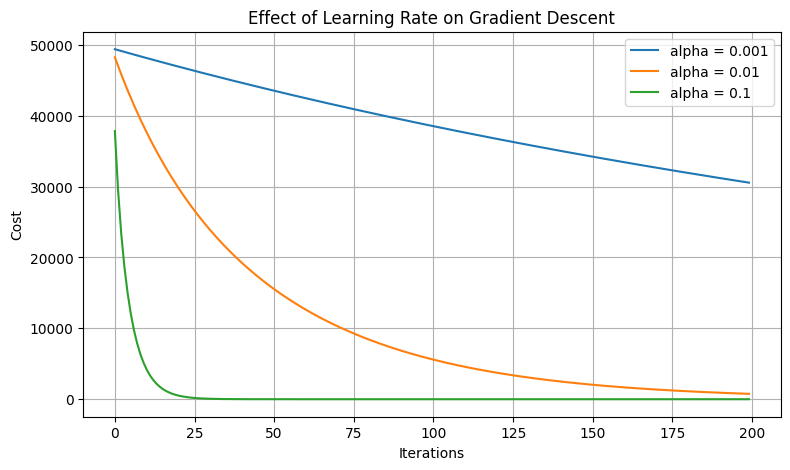

In [6]:
import numpy as np
import matplotlib.pyplot as plt
x_train=np.array([ [2104, 5, 1, 45],[1416, 3, 2, 40],[852,  2, 1, 35]])
y_train=np.array([460, 232, 178])
mu=np.mean(x_train,axis=0)
std=np.std(x_train,axis=0)
X_norm=(x_train-mu)/std
print(f"Normilised features :\n{X_norm}")
def predict(X,w,b):
  return np.dot(X,w)+b
def cost(X,y,w,b):
   m=X.shape[0]
   predictions=predict(X,w,b)
   errors=predictions-y
   cost_val=np.sum(errors**2)/(2*m)
   return cost_val
def compute_gradient(X,y,w,b):
    m,n=X.shape
    predictions=predict(X,w,b)
    errors=predictions-y
    dj_dw=np.dot(X.T,errors)/m
    dj_db=np.sum(errors)/m
    return dj_dw,dj_db
def gradient_descent(X,y,w,b,alpha,iterations):
    cost_history=[]

    for i in range(iterations):
        dj_dw, dj_db=compute_gradient(X,y,w,b)
        w=w-alpha*dj_dw
        b=b-alpha*dj_db
        c=cost(X,y,w,b)
        cost_history.append(c)
    return w,b,cost_history
learning_rates=[0.001, 0.01, 0.1]
iterations=200
plt.figure(figsize=(9,5))
for alpha in learning_rates:
    w_initial=np.zeros(X_norm.shape[1])
    b_initial=0.0
    w_final,b_final,cost_history=gradient_descent(X_norm,y_train,w_initial,b_initial,alpha,iterations)
    plt.plot(range(iterations),cost_history,label=f"alpha ={alpha}")
    print(f"Learning rate:{alpha} | "f"Initial cost:{cost(X_norm, y_train, w_initial, b_initial):.2f} | "f"Final cost:{cost_history[-1]:.4f}")
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Effect of Learning Rate on Gradient Descent")
plt.legend()
plt.grid(True)
plt.show()

Initial cost: 49518.0
Final cost: 5.795197618388157e+33


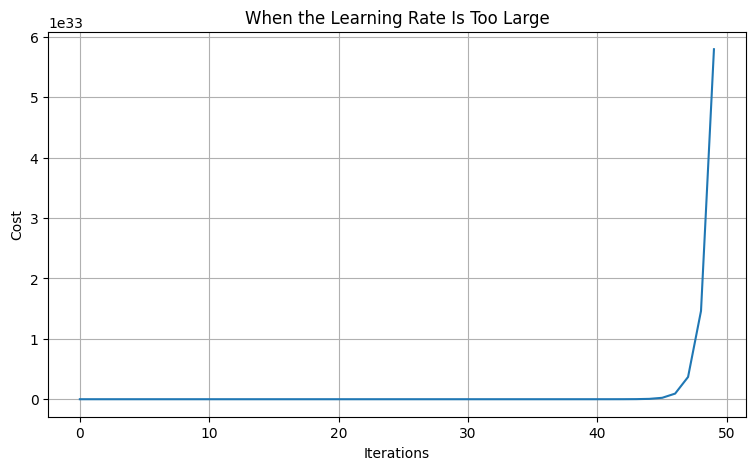

In [8]:
w_initial=np.zeros(X_norm.shape[1])
b_initial=0.0
w_final, b_final, cost_history = gradient_descent(X_norm,y_train,w_initial,b_initial,alpha=1.0,iterations=50)
print("Initial cost:",cost(X_norm,y_train,w_initial,b_initial))
print("Final cost:",cost_history[-1])
plt.figure(figsize=(9,5))
plt.plot(range(50),cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("When the Learning Rate Is Too Large")
plt.grid(True)
plt.show()